In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

pd.set_option("display.max_rows", 300)

In [2]:
DATA_PATH = "/Users/felixschulz/Library/CloudStorage/OneDrive-Personal/Dokumente/Job/UNI/Basel/Research/river-pollution-brazil/data/assembly/sensor_panel.parquet"

df = pd.read_parquet(DATA_PATH)

n_missing_year = df["year"].isna().sum()
if n_missing_year:
    print(f"Dropping {n_missing_year:,} rows with missing year")
    df = df.dropna(subset=["year"])
df["year"] = df["year"].astype(int)

n_pre_1970 = (df["year"] < 1970).sum()
if n_pre_1970:
    print(f"Dropping {n_pre_1970:,} rows with readings before 1970")
    df = df[df["year"] >= 1970]

df.shape

Dropping 553 rows with missing year


Dropping 2 rows with readings before 1970


(209157, 225)

# Sensor panel: descriptive statistics and regression-readiness diagnostics

This notebook is purely descriptive and diagnostic -- it does not fit a
model. Section 1 characterizes the assembled `sensor_panel` table on its
own terms: what every column contains, how complete and internally
consistent the data are, and what their distributions look like. Section 2
goes further and asks what a linear, fixed-effects panel regression of
water-quality outcomes on land-cover and climate covariates would require
of these data, then derives and checks the transformations that requirement
implies (log outcomes, additive-log-ratio land-cover shares) before any
such regression is estimated elsewhere.

## 1. Descriptive statistics

What the panel actually contains: every column (1.1), how much of it is
populated and how that coverage is distributed (1.2-1.3), what the
distributions and value ranges look like (1.4, 1.6), and whether the data
are internally consistent enough to trust (1.5). Nothing here assumes a
particular downstream model.

### 1.1 Column inventory

Every column falls into exactly one of six categories by naming
convention; the assertion below checks that the grouping is a true
partition of the panel (239 columns), not an approximation.

In [3]:
# Grouping columns once here (by name convention) lets every later table or
# plot iterate a category instead of relying on a hand-maintained list, and
# keeps this section honest about covering *all* columns rather than only
# the handful examined as regression candidates in section 2.
IDENTIFIER_COLS = ["station_code", "datetime", "date", "year", "trench_id", "system_id", "biome"]
METADATA_COLS = ["rained", "depth", "depth_parameter", "air_temperature", "sample_temperature"]
LAND_COVER_COLS_ALL = [c for c in df.columns if c.startswith("lc_") or c.startswith("alr_")]
STREAMFLOW_COLS_ALL = [c for c in df.columns if c.startswith("streamflow_")]
# `streamflow_discharge_mean_{7,31}d` also matches `"_mean_"`, hence the
# explicit exclusion -- streamflow is its own category, checked above.
CLIMATE_COLS_ALL = [c for c in df.columns if "_mean_" in c and not c.startswith("streamflow_")]
WATER_QUALITY_COLS_ALL = [
    c
    for c in df.columns
    if c
    not in {*IDENTIFIER_COLS, *METADATA_COLS, *LAND_COVER_COLS_ALL, *CLIMATE_COLS_ALL, *STREAMFLOW_COLS_ALL}
]

column_groups = {
    "identifier": IDENTIFIER_COLS,
    "metadata": METADATA_COLS,
    "land_cover": LAND_COVER_COLS_ALL,
    "climate": CLIMATE_COLS_ALL,
    "streamflow": STREAMFLOW_COLS_ALL,
    "water_quality": WATER_QUALITY_COLS_ALL,
}
grouped_total = sum(len(cols) for cols in column_groups.values())
assert grouped_total == df.shape[1], f"{grouped_total} grouped columns != {df.shape[1]} total columns"

pd.Series({name: len(cols) for name, cols in column_groups.items()}, name="n_columns").sort_values(ascending=False)

water_quality    130
climate           60
land_cover        16
identifier         7
streamflow         7
metadata           5
Name: n_columns, dtype: int64

### 1.2 Panel coverage

How many stations, years and biomes the panel spans, and how that
coverage is distributed over time and across stations -- a panel that
looks large in total rows can still be thin in any one dimension.

In [4]:
# Panel coverage
print(f"Observations: {len(df):,}")
print(f"Stations: {df['station_code'].nunique():,}")
print(f"Years: {df['year'].min()}–{df['year'].max()}")
print(f"Biomes: {sorted(df['biome'].dropna().unique().tolist())}")

df.groupby("biome").agg(
    n_obs=("station_code", "size"),
    n_stations=("station_code", "nunique"),
    year_min=("year", "min"),
    year_max=("year", "max"),
)

Observations: 209,157
Stations: 6,472
Years: 1970–2026
Biomes: ['Amazônia', 'Caatinga', 'Cerrado', 'Mata Atlântica', 'Pampa', 'Pantanal']


,n_obs,n_stations,year_min,year_max
biome,,,,
Amazônia,17959,687,1975,2026
Caatinga,17262,957,1976,2025
Cerrado,48107,1611,1970,2025
Mata Atlântica,116779,2912,1971,2025
Pampa,4851,218,1976,2024
Pantanal,4199,87,1978,2024


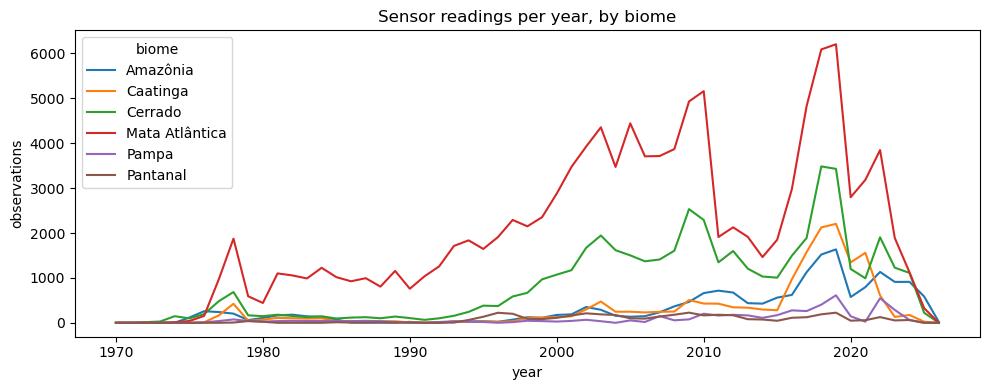

In [5]:
# Observations per year, by biome
obs_by_year_biome = df.groupby(["year", "biome"]).size().unstack("biome").fillna(0)

fig, ax = plt.subplots(figsize=(10, 4))
obs_by_year_biome.plot(ax=ax)
ax.set_ylabel("observations")
ax.set_title("Sensor readings per year, by biome")
plt.tight_layout()
plt.show()

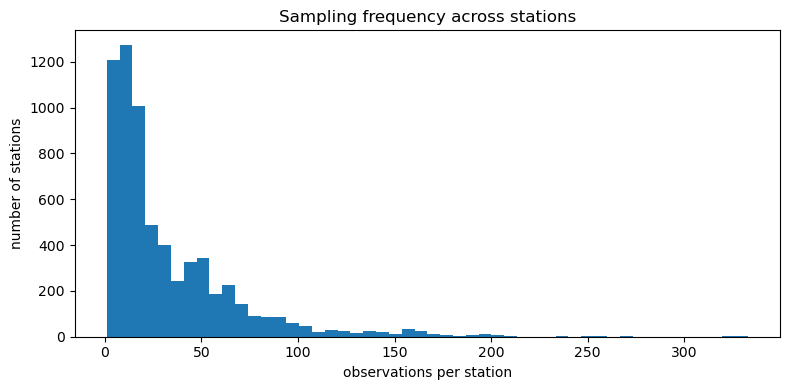

count    6472.000000
mean       32.317213
std        34.363204
min         1.000000
25%        10.000000
50%        19.000000
75%        46.000000
max       333.000000
dtype: float64

In [6]:
# Observations per station -- how concentrated is coverage in a few
# long-running stations vs. spread across many short-lived ones?
obs_per_station = df.groupby("station_code").size()

fig, ax = plt.subplots(figsize=(8, 4))
obs_per_station.plot(kind="hist", bins=50, ax=ax)
ax.set_xlabel("observations per station")
ax.set_ylabel("number of stations")
ax.set_title("Sampling frequency across stations")
plt.tight_layout()
plt.show()

obs_per_station.describe()

### 1.3 Missingness — all columns

Non-null counts for every column, not just the pasture/mining outcomes
examined later -- a column can look fine in isolation while being almost
entirely empty across the panel as a whole.

In [7]:
missingness = df.notna().sum().rename("n_obs").to_frame()
missingness["n_missing"] = len(df) - missingness["n_obs"]
missingness["missing_share"] = missingness["n_missing"] / len(df)
missingness = missingness.sort_values("missing_share", ascending=False)

print(f"Columns with zero missing values: {(missingness['missing_share'] == 0).sum()} of {len(missingness)}")
print(f"Columns missing >50% of rows: {(missingness['missing_share'] > 0.5).sum()}")
print(f"Columns missing entirely (100%): {(missingness['missing_share'] == 1.0).sum()}")

missingness

Columns with zero missing values: 8 of 225
Columns missing >50% of rows: 127
Columns missing entirely (100%): 0


,n_obs,n_missing,missing_share
enteropathogenic_bacteria,1,209156,0.999995
total_zooplankton,2,209155,0.999990
ammonia,6,209151,0.999971
salmonella,25,209132,0.999880
protozoa,26,209131,0.999876
coliphages,26,209131,0.999876
fungi,27,209130,0.999871
heterotrophic_bacteria,27,209130,0.999871
ethyl_azinphos,28,209129,0.999866
polychlorinated_biphenyls,29,209128,0.999861


### 1.4 Univariate summary, by category

`.describe()` plus skew/kurtosis for each column category, so heavy-tailed
or oddly-shaped distributions -- relevant again in section 2 -- are visible
category by category rather than buried in one 239-column table.

In [8]:
def describe_with_shape(frame, cols):
    """`.describe()` plus skew/kurtosis, to flag heavy-tailed columns that a
    mean/std/quantile table alone can hide."""
    summary = frame[cols].describe().T
    summary["skew"] = frame[cols].skew()
    summary["kurtosis"] = frame[cols].kurt()
    return summary


# ~150 raw water-quality parameters -- everything the sensor network
# measures, not just the pasture/mining outcome sets used in section 2.
describe_with_shape(df, WATER_QUALITY_COLS_ALL)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
ph,194467.0,7.002044e+00,8.999993e-01,0.0,6.600000,7.040000,7.460000,1.400000e+01,-1.497249,13.810714
color,30893.0,5.051574e+01,1.038240e+02,0.0,10.000000,27.000000,57.000000,5.820000e+03,21.390990,879.775927
turbidity,167370.0,4.992974e+01,2.874007e+02,0.0,6.700000,16.000000,38.000000,8.340000e+04,159.863210,43063.153969
electrical_conductivity,119318.0,1.892886e+02,3.549680e+03,0.0,36.000000,61.000000,120.000000,1.108198e+06,258.807576,79709.539926
total_hardness,22106.0,7.802526e+01,8.914170e+02,0.0,13.000000,23.200001,53.000000,1.180000e+05,107.639904,13918.490781
hardness,5576.0,4.040408e+01,9.959340e+01,0.0,7.700000,14.800000,35.127500,3.525000e+03,12.821552,315.818849
chemical_oxygen_demand,75669.0,3.925971e+01,5.371576e+02,0.0,8.000000,17.000000,35.000000,1.135200e+05,143.967272,27503.849949
biochemical_oxygen_demand,115898.0,7.110291e+00,1.844669e+02,0.0,2.000000,2.000000,4.000000,4.664000e+04,197.277363,44347.511499
dissolved_oxygen,185878.0,6.621183e+00,2.262807e+00,0.0,5.700000,7.000000,7.910000,4.000000e+01,0.253778,12.733588
total_solids,97173.0,2.803120e+02,4.467186e+03,0.0,59.000000,102.000000,184.000000,1.300000e+06,254.583347,73759.024132


In [9]:
# Land cover: raw distance-weighted shares (lc_*) and the additive-log-ratio
# regressors derived from them (alr_*) -- see the note above `ALR_COLS` in
# section 2.1 for why a regression would use the latter.
describe_with_shape(df, LAND_COVER_COLS_ALL)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
lc_forest,183608.0,0.407284,0.248152,0.00000,0.205963,0.357564,0.575151,1.000000,0.649930,-0.528184
lc_nonforest_nat,183608.0,0.050523,0.115416,0.00000,0.002829,0.013181,0.033473,1.000000,3.926784,17.030405
lc_pasture,183608.0,0.256321,0.201154,0.00000,0.079314,0.221536,0.403891,0.980092,0.564129,-0.646477
lc_agriculture,183608.0,0.110252,0.162427,0.00000,0.003401,0.030864,0.156866,0.957593,1.930016,3.398693
lc_farming_unclassified,183608.0,0.134741,0.101675,0.00000,0.042685,0.127448,0.206195,0.789789,0.574367,-0.060918
lc_urban,183608.0,0.026896,0.076814,0.00000,0.001261,0.004779,0.017889,1.000000,7.296392,71.190070
lc_mining,183608.0,0.001234,0.006961,0.00000,0.000000,0.000000,0.000221,0.333427,15.513441,389.118776
lc_other,183608.0,0.001451,0.002527,0.00000,0.000280,0.000762,0.001633,0.086867,7.833099,129.992792
lc_water,183608.0,0.011298,0.022545,0.00000,0.001370,0.004231,0.011162,0.525641,6.719601,84.623734
lc_nat,183608.0,0.457807,0.257876,0.00000,0.239000,0.414008,0.652153,1.000000,0.418691,-0.918785


In [10]:
# Climate: each ERA5-Land variable at every distance-weighted window
# (mean_day/7d/30d/90d/180d/365d).
describe_with_shape(df, CLIMATE_COLS_ALL)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
2t_mean_day,182951.0,22.355910,4.290153,3.321704e-01,19.689814,22.901363,25.516306,34.999173,-0.609632,0.295066
2t_mean_7d,182951.0,22.344904,4.058878,2.967376e+00,19.708172,22.816246,25.401084,34.545500,-0.496533,-0.062385
2t_mean_30d,182951.0,22.357194,3.873562,8.286599e+00,19.786651,22.787490,25.346944,32.945655,-0.439127,-0.314766
2t_mean_90d,182951.0,22.362644,3.683533,9.477493e+00,19.881590,22.718950,25.275057,32.621637,-0.408189,-0.429852
2t_mean_180d,182951.0,22.432900,3.369509,1.118574e+01,19.990917,22.633462,25.189825,31.356202,-0.292523,-0.611577
2t_mean_365d,182951.0,22.473865,3.091787,1.360447e+01,19.927371,22.519898,25.106887,30.073150,-0.065660,-1.002719
2d_mean_day,182951.0,16.818548,4.381271,-5.288364e+00,13.809794,17.339128,20.190939,25.892262,-0.532452,-0.071849
2d_mean_7d,182951.0,16.820668,4.080564,-1.713000e+00,13.820202,17.206657,19.934876,25.286293,-0.321561,-0.551691
2d_mean_30d,182951.0,16.819001,3.853450,4.420358e+00,13.850172,17.113524,19.738983,24.985881,-0.186765,-0.758870
2d_mean_90d,182951.0,16.841951,3.605443,5.800736e+00,13.984277,17.062831,19.516747,24.842332,-0.066159,-0.824829


In [11]:
# Streamflow match quality (nearest-gauge distance/weight/coverage), not
# just the discharge values themselves.
describe_with_shape(df, STREAMFLOW_COLS_ALL)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
streamflow_discharge_day,197882.0,3531.836507,12908.727430,0.0,105.110353,616.729209,1693.667670,250781.765625,6.916718,60.258242
streamflow_discharge_mean_7d,197924.0,3524.003724,12896.652203,0.0,106.610141,620.525871,1681.065994,251685.975446,6.921093,60.403775
streamflow_discharge_mean_31d,197999.0,3526.946997,12884.749664,0.0,110.700569,631.800328,1701.971588,252628.632560,6.946518,61.120807
streamflow_match_count,209157.0,19.427956,33.973430,0.0,5.000000,12.000000,23.000000,569.000000,7.359598,74.182356
streamflow_nonnull_day_count,209157.0,18.558528,32.704567,0.0,5.000000,11.000000,22.000000,541.000000,7.272897,72.401685
streamflow_total_weight,209157.0,18.148340,30.417751,0.0,4.949322,11.141133,21.277667,500.432760,7.141700,70.982951
streamflow_nearest_distance_m,198481.0,29.218354,100.970614,0.0,0.000000,0.000000,21.487879,3214.639510,9.064284,106.286007


In [12]:
# Sample-level metadata recorded alongside each reading.
describe_with_shape(df, METADATA_COLS)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
rained,143249.0,0.125174,0.337476,0.0,0.00,0.00,0.0,2.0,2.435233,4.559204
depth,70661.0,1.553507,27.135241,0.0,0.20,0.30,0.5,5000.0,121.151079,19141.488047
depth_parameter,384.0,10.105388,73.490233,0.0,0.35,0.56,1.5,1044.0,11.485755,139.779677
air_temperature,160295.0,26.116299,5.461767,-1.0,23.00,27.00,30.0,59.0,-0.909186,2.356937
sample_temperature,201489.0,23.729264,4.634361,0.0,21.00,24.18,27.0,58.0,-0.926863,2.561773


### 1.5 Data-quality checks

Checks that would each, on their own, undermine any later use of the
panel if they failed: duplicate readings, implausible values outside a
variable's physical range, and negative values where none should exist.

In [13]:
# Exact-duplicate (station_code, datetime) rows would silently double-count
# a reading in any downstream aggregation or regression.
n_duplicate_readings = df.duplicated(subset=["station_code", "datetime"]).sum()
print(f"Duplicate (station_code, datetime) rows: {n_duplicate_readings:,} of {len(df):,}")

Duplicate (station_code, datetime) rows: 0 of 209,157


In [14]:
# Per-station temporal coverage: how long each station has run and how
# regularly it's been sampled (a station with a few widely-spaced readings
# contributes very differently to a panel regression than a densely sampled
# one).
def _median_gap_days(datetimes):
    gaps = datetimes.sort_values().diff().dt.days.dropna()
    return gaps.median() if len(gaps) else float("nan")


station_coverage = df.groupby("station_code").agg(
    n_obs=("datetime", "size"),
    first_obs=("datetime", "min"),
    last_obs=("datetime", "max"),
)
station_coverage["span_years"] = (station_coverage["last_obs"] - station_coverage["first_obs"]).dt.days / 365.25
station_coverage["median_gap_days"] = df.groupby("station_code")["datetime"].apply(_median_gap_days)

station_coverage.describe()

,n_obs,first_obs,last_obs,span_years,median_gap_days
count,6472.000000,6472,6472,6472.000000,6346.000000
mean,32.317213,2005-02-28 07:46:57.359548,2018-05-15 21:59:39.078028,13.207814,116.075481
min,1.000000,1970-09-14 10:30:00,1977-04-18 13:00:00,0.000000,1.000000
25%,10.000000,1998-08-30 19:55:00,2018-02-06 12:06:15,3.766598,88.500000
50%,19.000000,2006-10-02 22:00:00,2021-11-20 09:59:30,6.807666,91.500000
75%,46.000000,2017-04-04 12:56:15,2023-04-11 00:00:00,20.788501,107.000000
max,333.000000,2025-03-13 14:00:00,2026-02-26 09:16:00,54.217659,7345.000000
std,34.363204,NaN,NaN,13.171388,209.328952


In [15]:
# Implausible values: physically bounded quantities that fall outside their
# valid range point to an upstream unit/parsing issue rather than a genuine
# reading. `PHYSICAL_LIMITS` is the same bound dict the cleaning pipeline
# itself enforces (src.data.sources.sensor_data.schema) -- checking the
# assembled panel against it catches anything that slipped through cleaning
# or was introduced by a later join, instead of keeping a second,
# potentially-stale copy of the same bounds here. Covers pH plus five other
# physically-bounded measurements (temperatures, dissolved oxygen, oxygen
# saturation, the water-quality index).
from src.data.sources.sensor_data.schema import PHYSICAL_LIMITS, VERY_LARGE_SUSPECT_THRESHOLDS

physical_range_checks = {}
for column, (lower, upper) in PHYSICAL_LIMITS.items():
    if column not in df.columns:
        continue
    n_non_null = int(df[column].notna().sum())
    n_out_of_range = int(((df[column] < lower) | (df[column] > upper)).sum())
    physical_range_checks[column] = {
        "valid_range": f"[{lower:g}, {upper:g}]",
        "n_non_null": n_non_null,
        "n_out_of_range": n_out_of_range,
        "share_out_of_range": n_out_of_range / n_non_null if n_non_null else float("nan"),
    }

pd.DataFrame(physical_range_checks).T

,valid_range,n_non_null,n_out_of_range,share_out_of_range
air_temperature,"[-10, 60]",160295,0,0.0
ph,"[0, 14]",194467,0,0.0
dissolved_oxygen,"[0, 40]",185878,0,0.0
sample_temperature,"[0, 60]",201489,0,0.0


In [16]:
# Land-cover shares have their own physical bound ([0, 1]) not covered by
# PHYSICAL_LIMITS above, which is specific to sensor_data measurements.
lc_raw_cols = [c for c in LAND_COVER_COLS_ALL if c.startswith("lc_")]
lc_out_of_range = pd.Series(
    {col: int(((df[col] < 0) | (df[col] > 1)).sum()) for col in lc_raw_cols},
    name="n_out_of_range",
)
lc_out_of_range = lc_out_of_range[lc_out_of_range > 0]
print(f"Land-cover share columns with values outside [0, 1]: {len(lc_out_of_range)} of {len(lc_raw_cols)}")
lc_out_of_range

Land-cover share columns with values outside [0, 1]: 0 of 10


Series([], Name: n_out_of_range, dtype: int64)

In [17]:
# Metals with a known "suspiciously large" threshold in the cleaning
# pipeline (VERY_LARGE_SUSPECT_THRESHOLDS, same module as above) -- not a
# hard physical impossibility like PHYSICAL_LIMITS, but large enough (e.g.
# mg/L recorded where µg/L was intended) to be worth a second look rather
# than taking at face value.
metal_suspect_counts = {}
for column, threshold in VERY_LARGE_SUSPECT_THRESHOLDS.items():
    if column not in df.columns:
        continue
    metal_suspect_counts[column] = int((df[column] > threshold).sum())

metal_suspect_counts = pd.Series(metal_suspect_counts, name="n_above_suspect_threshold")
metal_suspect_counts = metal_suspect_counts[metal_suspect_counts > 0]
print(
    f"Columns with values above their suspect threshold: {len(metal_suspect_counts)} "
    f"of {len(VERY_LARGE_SUSPECT_THRESHOLDS)} checked"
)
metal_suspect_counts

Columns with values above their suspect threshold: 0 of 5 checked


Series([], Name: n_above_suspect_threshold, dtype: int64)

In [18]:
# Everything else measured by the sensor network (concentrations, counts,
# solids fractions, alkalinity, discharge, ...) is non-negative by
# construction; `alr_*` is excluded since it's a log-ratio and can be
# negative by design.
NONNEGATIVE_COLS = [c for c in WATER_QUALITY_COLS_ALL if c != "ph"] + STREAMFLOW_COLS_ALL
negative_counts = pd.Series(
    {col: int((df[col] < 0).sum()) for col in NONNEGATIVE_COLS},
    name="n_negative",
)
negative_counts = negative_counts[negative_counts > 0].sort_values(ascending=False)
print(f"Columns with at least one negative value: {len(negative_counts)} of {len(NONNEGATIVE_COLS)} checked")
negative_counts

Columns with at least one negative value: 0 of 136 checked


Series([], Name: n_negative, dtype: int64)

### 1.6 Distributions

Visualizes the shapes the summary tables in 1.4 only describe numerically
-- long right tails in the water-quality parameters (section 2.2 asks what
that implies for a regression), and the compositional, sum-to-one
structure of land-cover shares (section 2.3).

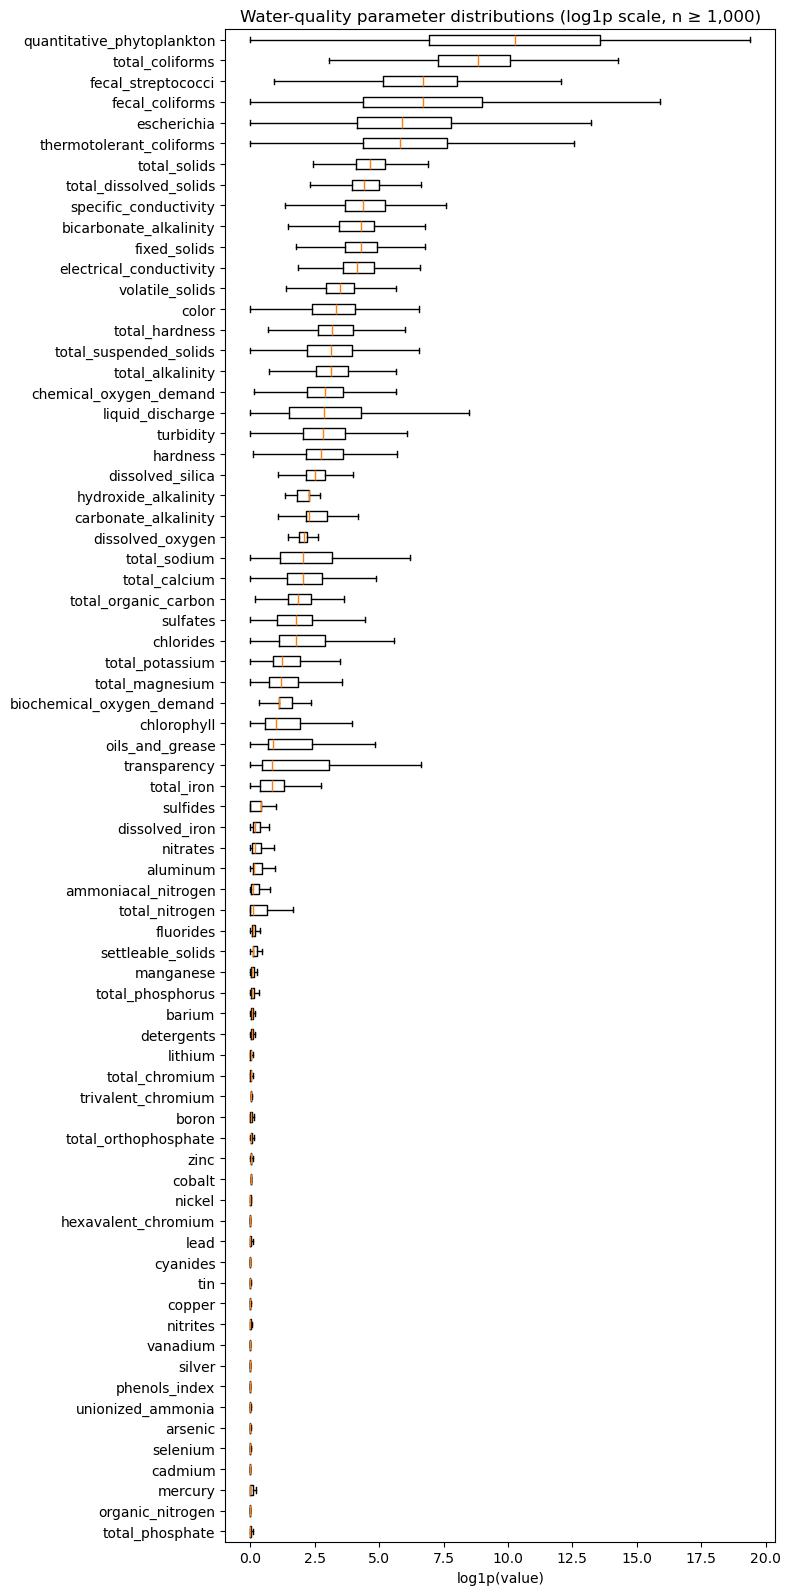

In [19]:
# Water-quality parameters are famously long-tailed; a log1p boxplot across
# every parameter with enough coverage to be meaningful shows that shape at
# a glance, which the summary tables in 1.4 can't. Negative values (see 1.5)
# are clipped to 0 before the log so a handful of QA artifacts can't break
# the transform.
MIN_OBS_FOR_DISTRIBUTION_PLOT = 1000
plot_cols = [
    c for c in WATER_QUALITY_COLS_ALL if c != "ph" and df[c].notna().sum() >= MIN_OBS_FOR_DISTRIBUTION_PLOT
]
log_values = {col: np.log1p(df[col].clip(lower=0)).dropna() for col in plot_cols}
plot_cols = sorted(plot_cols, key=lambda col: log_values[col].median())

fig, ax = plt.subplots(figsize=(8, min(40, max(6, 0.22 * len(plot_cols)))))
ax.boxplot([log_values[col] for col in plot_cols], vert=False, tick_labels=plot_cols, showfliers=False)
ax.set_xlabel("log1p(value)")
ax.set_title(f"Water-quality parameter distributions (log1p scale, n ≥ {MIN_OBS_FOR_DISTRIBUTION_PLOT:,})")
plt.tight_layout()
plt.show()

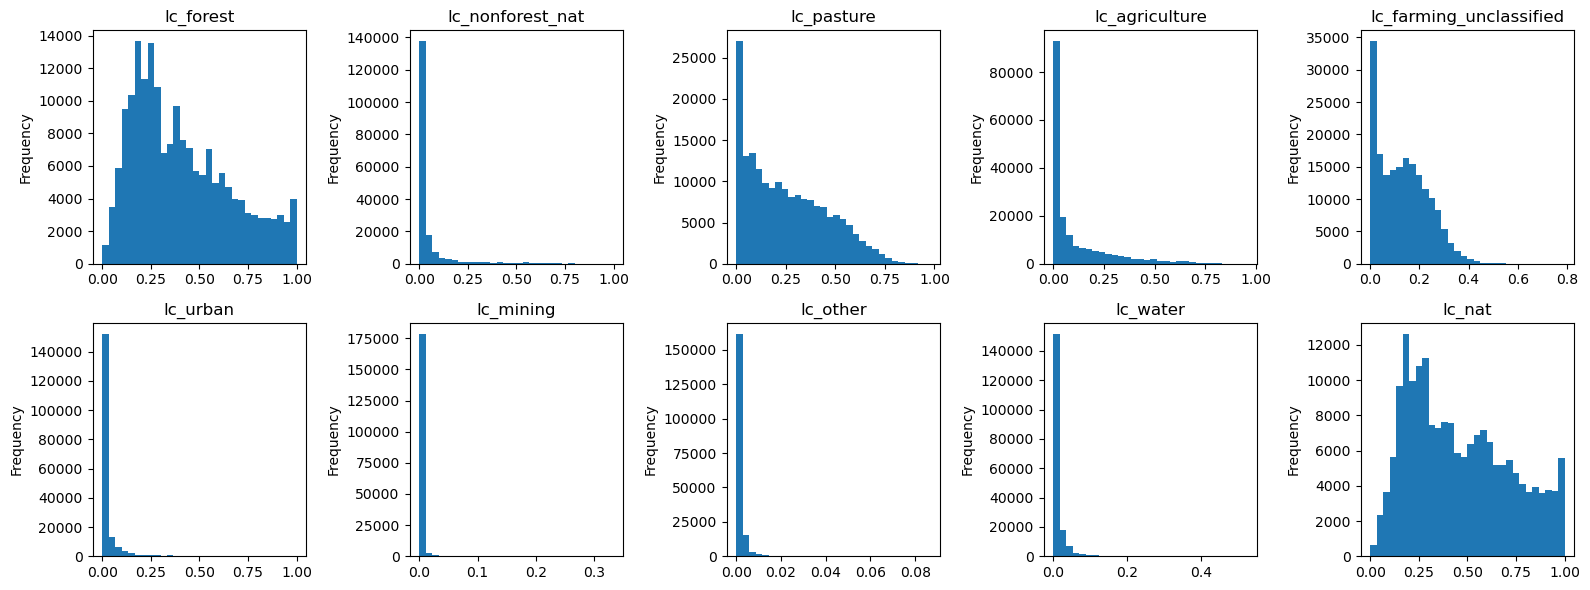

In [20]:
# Land-cover shares are compositional (bounded in [0, 1]) -- a boxplot
# compresses that shape, so these get individual histograms instead.
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.flat, lc_raw_cols):
    df[col].dropna().plot(kind="hist", bins=30, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(lc_raw_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Requirements for linear regression: diagnostics and transformations

A fixed-effects panel regression of a water-quality outcome on land-cover
and climate covariates -- something in the shape of

```
log(outcome) ~ land_cover + climate | station + biome×year
```

clustered by basin and year -- asks more of the data than the descriptive
checks in section 1. Four requirements matter most, and each motivates a
specific transformation or check:

1. **Reasonably well-behaved outcomes.** OLS in logs down-weights extreme
   observations relative to levels; if an outcome is heavily right-skewed
   (common for concentrations and counts), estimating in logs rather than
   levels is close to necessary, not a stylistic choice (2.2).
2. **Non-degenerate regressors.** Land-cover shares sum to (approximately)
   one by construction, so using every raw share as a regressor is exactly
   collinear -- the compositional-data analogue of the dummy-variable trap.
   An additive-log-ratio (ALR) transform against a natural-land reference
   removes that structural dependency (2.3).
3. **Multicollinearity kept in check** among whatever regressors remain,
   since land-cover conversion and weather/soil-moisture variables can move
   together even after the ALR transform (2.4).
4. **Enough within-unit variation** left after absorbing the fixed effects,
   and **enough clusters** for the standard errors to be trustworthy --
   otherwise the fixed-effects/clustering choice itself, rather than the
   coefficients, becomes the binding constraint (2.5, 2.6).

No model is estimated in this notebook; the subsections below check each
requirement against the actual panel and build the transformed variables
(`alr_*`, `log_*`) that a regression would use.

### 2.1 Candidate outcomes and regressors

A tentative outcome/regressor set, carried over unchanged into whichever
notebook eventually fits the model -- defined here so the diagnostics
below have concrete columns to check.

In [21]:
# --- Variable name mapping --------------------------------------------------
# The panel stores land cover two ways (src/data/land_cover/composition.py):
# raw distance-weighted shares under lc_* (used for descriptives), and
# additive-log-ratio (alr_*) transforms against the combined natural-land
# reference (lc_forest + lc_nonforest_nat, i.e. c1+c2 -- not forest alone, so
# Cerrado/Caatinga's natural non-forest state isn't miscoded as disturbance),
# with a pseudocount before the ratio and a single inv-sqrt-distance kernel
# weight per bucket. That's the correctly-specified regressor: coefficients
# on alr_pasture etc. read as "effect of converting natural vegetation to
# pasture/etc.", consistent across biomes. lc_pasture_dw/lc_agri_dw/... in
# the spec therefore map to alr_pasture/alr_agriculture/alr_urban/alr_mining/
# alr_other; lc_* (raw shares) is kept only for descriptive statistics.
#
# Climate covariates are renamed from the panel's `<var>_mean_<window>`
# naming to the spec's short names; `2t_mean_365d` is additionally renamed
# because a leading digit is not a valid formula identifier for pyfixest.
CLIMATE_RENAME = {
    "tp_mean_day": "tp_1",
    "tp_mean_7d": "tp_7",
    "sro_mean_7d": "sro_7",
    "swvl1_mean_30d": "swvl1_30",
    "swvl2_mean_90d": "swvl2_90",
    "ssro_mean_180d": "ssro_180",
    "tp_mean_365d": "tp_365",
    "pev_mean_365d": "pev_365",
    "2t_mean_365d": "t2m_365",
}
df = df.rename(columns=CLIMATE_RENAME)

LC_COLS = ["lc_pasture", "lc_agriculture", "lc_urban", "lc_mining", "lc_other"]
ALR_COLS = ["alr_pasture", "alr_agriculture", "alr_urban", "alr_mining", "alr_other"]
CLIMATE_COLS = list(CLIMATE_RENAME.values())

# A candidate spec would cluster on `basin_id`. `system_id` (a
# disconnected-river-system identifier, i.e. connected component of the flow
# graph -- see src.data.river_network.core) is the real basin unit and has
# been wired into setup/assembly_datasets.yaml as a new `river_system` source
# joined on trench_id (100% match rate against the current panel). It isn't
# in this copy of the panel yet because assembly needs to be rerun on HPC;
# 2.6 falls back to two-way clustering on station_code + year until then,
# and would pick up system_id automatically once the panel is regenerated.
CLUSTER_VARS = "system_id+year" if "system_id" in df.columns else "station_code+year"

# Pasture-associated pollution: fecal indicators, nutrients, organic load,
# algal/cyanobacterial response, and physical (turbidity/solids/oxygen) signals.
# `cyanobacteria_density` is absent from this panel refresh (along with 13
# other water-quality columns not used as outcomes here) and is excluded
# until it reappears upstream.
PASTURE_OUTCOMES = [
    "thermotolerant_coliforms", "fecal_coliforms", "escherichia",
    "total_nitrogen", "ammoniacal_nitrogen", "total_phosphorus",
    "biochemical_oxygen_demand", "chemical_oxygen_demand",
    "chlorophyll",
    "turbidity", "total_suspended_solids",
    "dissolved_oxygen",
]

# Mining-associated pollution: metals/metalloids, sulfates, conductivity,
# solids/turbidity, and (sometimes) pH/oxygen.
MINING_OUTCOMES = [
    "arsenic", "cadmium", "lead", "mercury", "manganese", "copper", "zinc",
    "aluminum", "sulfates", "electrical_conductivity",
    "total_suspended_solids", "turbidity", "ph", "dissolved_oxygen",
]

OUTCOME_GROUPS = {"pasture": PASTURE_OUTCOMES, "mining": MINING_OUTCOMES}
ALL_OUTCOMES = sorted(set(PASTURE_OUTCOMES) | set(MINING_OUTCOMES))

In [22]:
# Outcome variables: coverage + distribution
outcome_coverage = df[ALL_OUTCOMES].notna().sum().rename("n_obs").to_frame()
outcome_coverage["missing_share"] = 1 - outcome_coverage["n_obs"] / len(df)
outcome_coverage.sort_values("n_obs", ascending=False)

,n_obs,missing_share
ph,194467,0.070234
dissolved_oxygen,185878,0.111299
turbidity,167370,0.199788
electrical_conductivity,119318,0.429529
biochemical_oxygen_demand,115898,0.445880
ammoniacal_nitrogen,101360,0.515388
total_phosphorus,97078,0.535861
chemical_oxygen_demand,75669,0.638219
fecal_coliforms,74693,0.642885
total_nitrogen,68589,0.672069


In [23]:
df[ALL_OUTCOMES].describe().T

,count,mean,std,min,25%,50%,75%,max
aluminum,11964.0,1.660991,3.721558e+01,0.0,0.100000,0.1700,0.55000,2.500000e+03
ammoniacal_nitrogen,101360.0,1.020679,1.122934e+01,0.0,0.040000,0.1000,0.40000,2.709000e+03
arsenic,12103.0,0.013828,1.264925e-01,0.0,0.000500,0.0012,0.01000,6.300000e+00
biochemical_oxygen_demand,115898.0,7.110291,1.844669e+02,0.0,2.000000,2.0000,4.00000,4.664000e+04
cadmium,31440.0,0.008787,2.618488e-01,0.0,0.000500,0.0010,0.00200,4.000000e+01
chemical_oxygen_demand,75669.0,39.259714,5.371576e+02,0.0,8.000000,17.0000,35.00000,1.135200e+05
chlorophyll,26629.0,13.520089,1.054664e+02,0.0,0.801000,1.7600,5.91000,9.718800e+03
copper,26226.0,0.020785,3.376241e-01,0.0,0.004000,0.0080,0.01000,5.100000e+01
dissolved_oxygen,185878.0,6.621183,2.262807e+00,0.0,5.700000,7.0000,7.91000,4.000000e+01
electrical_conductivity,119318.0,189.288601,3.549680e+03,0.0,36.000000,61.0000,120.00000,1.108198e+06


In [24]:
# Land-cover (raw shares + additive-log-ratio regressors) and climate covariates
df[LC_COLS + ALR_COLS + CLIMATE_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
lc_pasture,183608.0,0.256321,0.201154,0.000000e+00,0.079314,0.221536,0.403891,0.980092
lc_agriculture,183608.0,0.110252,0.162427,0.000000e+00,0.003401,0.030864,0.156866,0.957593
lc_urban,183608.0,0.026896,0.076814,0.000000e+00,0.001261,0.004779,0.017889,1.000000
lc_mining,183608.0,0.001234,0.006961,0.000000e+00,0.000000,0.000000,0.000221,0.333427
lc_other,183608.0,0.001451,0.002527,0.000000e+00,0.000280,0.000762,0.001633,0.086867
alr_pasture,183608.0,-1.095896,2.188926,-9.210440e+00,-1.918454,-0.591638,0.391204,6.869574
alr_agriculture,183608.0,-3.005820,2.972647,-9.210440e+00,-4.895377,-2.596745,-0.706268,3.920805
alr_urban,183608.0,-4.390462,2.397335,-9.210440e+00,-5.966459,-4.287143,-2.638738,9.210440
alr_mining,183608.0,-7.449803,1.459964,-9.210440e+00,-8.577128,-7.769868,-6.721970,0.000000
alr_other,183608.0,-6.133348,1.333183,-9.210440e+00,-6.963526,-6.003759,-5.211968,0.000000


### 2.2 Outcome skew: why the outcomes get logged

Compares skewness/kurtosis of each candidate outcome in levels vs. in
`log(outcome)` (non-positive values dropped, as a regression would drop
them too). A large drop in `|skew|` after logging is the data-driven case
for estimating in logs rather than levels.

In [25]:
log_outcomes = pd.DataFrame({
    outcome: np.log(df[outcome].where(df[outcome] > 0))
    for outcome in ALL_OUTCOMES
})

skew_comparison = pd.DataFrame({
    "skew_level": df[ALL_OUTCOMES].skew(),
    "skew_log": log_outcomes.skew(),
    "kurtosis_level": df[ALL_OUTCOMES].kurt(),
    "kurtosis_log": log_outcomes.kurt(),
})
skew_comparison["abs_skew_reduction"] = (
    skew_comparison["skew_level"].abs() - skew_comparison["skew_log"].abs()
)
skew_comparison.sort_values("abs_skew_reduction", ascending=False)

,skew_level,skew_log,kurtosis_level,kurtosis_log,abs_skew_reduction
electrical_conductivity,258.807576,-1.488040,79709.539926,10.769568,257.319536
ammoniacal_nitrogen,198.360140,0.713441,44240.296793,0.575895,197.646699
biochemical_oxygen_demand,197.277363,1.309375,44347.511499,3.588407,195.967988
total_suspended_solids,183.208638,0.098489,36772.768937,0.778125,183.110148
turbidity,159.863210,-0.237169,43063.153969,2.125852,159.626040
chemical_oxygen_demand,143.967272,0.207390,27503.849949,1.416612,143.759882
copper,134.006678,0.834349,19907.671652,2.763763,133.172329
cadmium,124.495357,1.046571,17991.007517,3.186524,123.448786
total_phosphorus,116.526430,0.720296,15674.120355,1.624432,115.806134
fecal_coliforms,113.376515,-0.030181,14547.472486,0.354598,113.346335


### 2.3 Land-cover compositionality: why shares get ALR-transformed

The panel's raw land-cover shares (`lc_forest`, `lc_nonforest_nat`,
`lc_pasture`, `lc_agriculture`, `lc_farming_unclassified`, `lc_urban`,
`lc_mining`, `lc_other`, `lc_water`) are components of one composition: for
any pixel neighborhood they should sum to 1. That constraint mechanically
induces negative correlation among them -- more of one share necessarily
means less of another -- so using several raw shares as regressors at once
is close to collinear by construction, not because of any real economic
relationship. The additive-log-ratio transform (`alr_*`, section 2.1)
breaks that constraint by expressing each disturbed-land category as a log
ratio against the natural-land reference, at the cost of making natural
land the implicit omitted category.

lc_* components sum to exactly 1 in 87.8% of rows (the remainder are rows with incomplete land-cover coverage, mostly summing to 0); they are shares of one composition, not independent measurements.


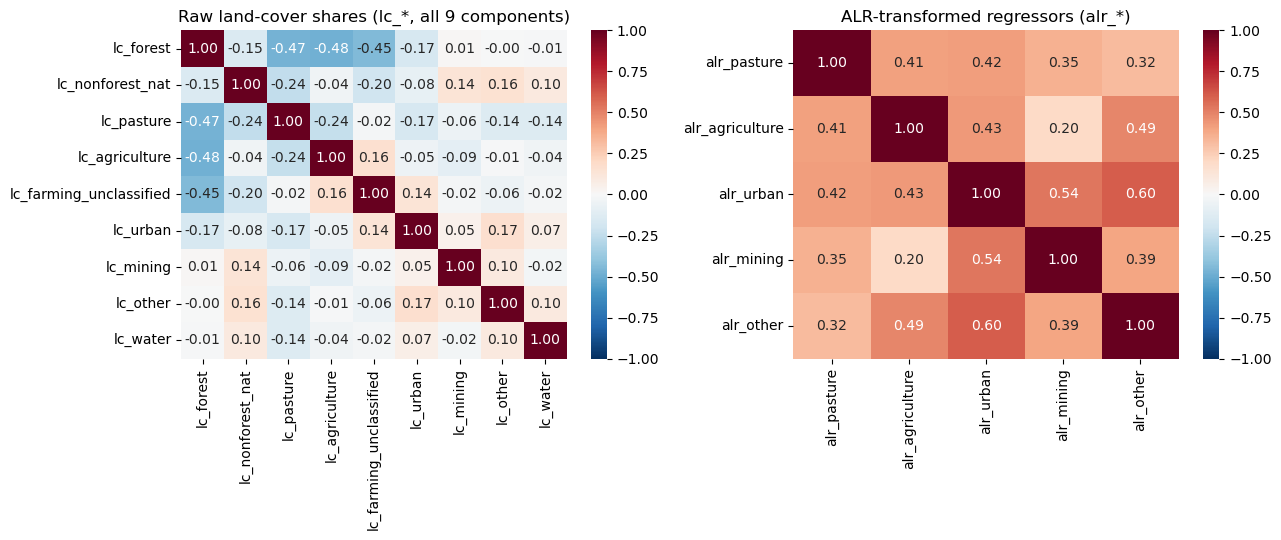

In [26]:
LC_COMPONENT_COLS = [
    "lc_forest", "lc_nonforest_nat", "lc_pasture", "lc_agriculture",
    "lc_farming_unclassified", "lc_urban", "lc_mining", "lc_other", "lc_water",
]
component_sum = df[LC_COMPONENT_COLS].sum(axis=1)
share_summing_to_one = (component_sum.round(6) == 1).mean()
print(
    f"lc_* components sum to exactly 1 in {share_summing_to_one:.1%} of rows "
    "(the remainder are rows with incomplete land-cover coverage, mostly "
    "summing to 0); they are shares of one composition, not independent "
    "measurements."
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sns.heatmap(df[LC_COMPONENT_COLS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Raw land-cover shares (lc_*, all 9 components)")
sns.heatmap(df[ALR_COLS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("ALR-transformed regressors (alr_*)")
plt.tight_layout()
plt.show()

### 2.4 Multicollinearity among final regressors

The ALR transform removes the *mechanical* compositional constraint, but
land-cover conversion and weather/soil-moisture variables can still move
together for genuine reasons (e.g. pasture expansion concentrated in drier
regions). A correlation heatmap catches pairwise relationships; variance
inflation factors (VIF) also catch multicollinearity that only shows up
jointly, e.g. one regressor as a near-linear combination of several others.
VIF > 10 is the conventional threshold for "this coefficient's standard
error is doing a lot of extra work."

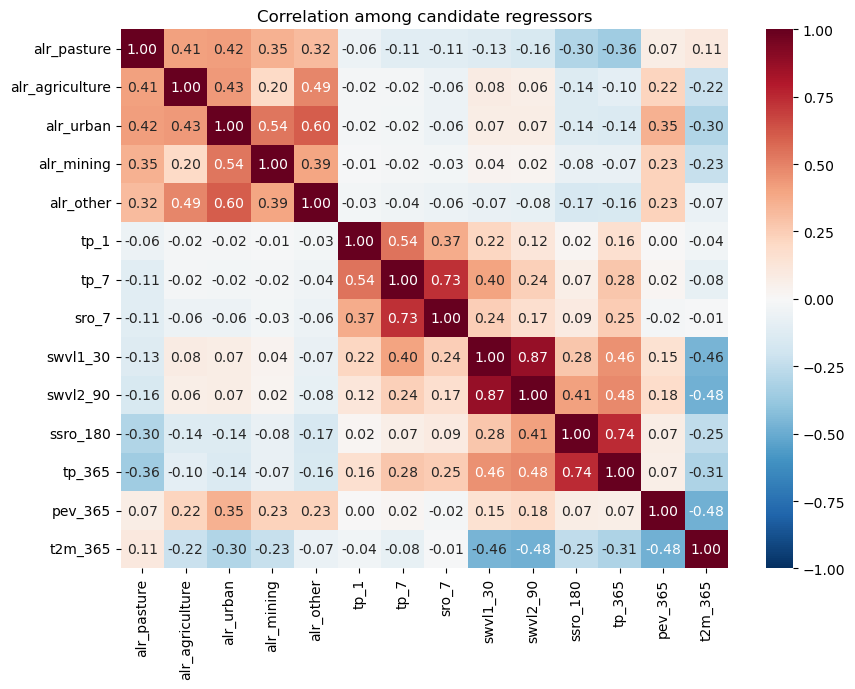

In [27]:
# Correlation among the candidate regressors -- not the full climate set
# from 1.4, just the columns a regression would actually use.
corr = df[ALR_COLS + CLIMATE_COLS].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation among candidate regressors")
plt.tight_layout()
plt.show()

In [28]:
vif_cols = ALR_COLS + CLIMATE_COLS
vif_data = df[vif_cols].dropna()
X = add_constant(vif_data)

vif = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
    index=vif_cols,
    name="VIF",
).sort_values(ascending=False)
vif

swvl1_30           5.580313
swvl2_90           5.188405
tp_7               3.139110
tp_365             2.963827
ssro_180           2.624454
alr_urban          2.300541
sro_7              2.247598
t2m_365            1.956796
alr_other          1.904568
alr_pasture        1.654655
alr_agriculture    1.622728
alr_mining         1.538672
tp_1               1.427066
pev_365            1.411311
Name: VIF, dtype: float64

### 2.5 Within-unit variation for the planned fixed effects

`station_code` and `biome×year` fixed effects would absorb all
cross-sectional and biome-by-year variation; only the variation left
*within* each station can identify a coefficient. If a regressor barely
varies within station -- e.g. because land cover changes slowly and most
of its variance is cross-sectional, between one station's surroundings and
another's -- the fixed effects absorb nearly all of its useful variation
and any estimate built on what's left will be imprecise no matter how
large the raw sample looks.

In [29]:
def within_station_variance_share(frame, cols, group_col="station_code"):
    """Share of each column's variance that survives demeaning by `group_col`
    -- the variance a `group_col` fixed effect would leave available to
    identify a coefficient."""
    demeaned = frame[cols] - frame.groupby(group_col)[cols].transform("mean")
    return (demeaned.var() / frame[cols].var()).rename("within_station_variance_share")


within_station_variance_share(df, ALR_COLS + CLIMATE_COLS + list(log_outcomes.columns)).sort_values()

alr_urban                    0.009307
alr_pasture                  0.011542
t2m_365                      0.020603
alr_mining                   0.022221
alr_agriculture              0.022990
pev_365                      0.039803
alr_other                    0.043102
tp_365                       0.203721
escherichia                  0.294029
swvl2_90                     0.331392
manganese                    0.353317
swvl1_30                     0.418246
dissolved_oxygen             0.497263
zinc                         0.498494
arsenic                      0.500501
ssro_180                     0.505059
sulfates                     0.588857
ph                           0.636818
mercury                      0.655985
turbidity                    0.764134
total_nitrogen               0.801294
aluminum                     0.803164
total_suspended_solids       0.826587
chlorophyll                  0.849175
total_phosphorus             0.855467
sro_7                        0.861899
biochemical_

### 2.6 Cluster count for the clustering dimension

Cluster-robust standard errors are only reliable with enough clusters --
as a rule of thumb, inference gets shaky below roughly 30-50 clusters.
`system_id` isn't in this copy of the panel yet (see the note above
`CLUSTER_VARS` in 2.1); this checks how many clusters the fallback
(`station_code`×`year`) actually has, since a regression run today
would have to use it.

In [30]:
cluster_cols = CLUSTER_VARS.split("+")
n_clusters = df[cluster_cols].drop_duplicates().shape[0]
print(f"Clustering on {CLUSTER_VARS}: {n_clusters:,} distinct clusters")
for col in cluster_cols:
    print(f"  {col}: {df[col].nunique():,} distinct values")

Clustering on system_id+year: 4,554 distinct clusters
  system_id: 261 distinct values
  year: 56 distinct values


### 2.7 Interaction terms for Spec 1 (`alr_pasture:sro_7`, `alr_agriculture:sro_7`)

Spec 1 interacts land-cover conversion with 7-day surface runoff, on the
idea that pollution from a converted landscape is runoff-mediated. Two
things the diagnostics above don't cover once interaction terms are added:
whether the interaction terms themselves are collinear with the main
effects they're built from, and whether `sro_7` actually varies across the
range of `alr_pasture`/`alr_agriculture` -- if high-pasture stations only
ever see a narrow slice of runoff values, the interaction coefficient is
extrapolating rather than estimating anything the data support.

In [31]:
df["alr_pasture_x_sro_7"] = df["alr_pasture"] * df["sro_7"]
df["alr_agriculture_x_sro_7"] = df["alr_agriculture"] * df["sro_7"]

vif_cols_spec1 = ALR_COLS + CLIMATE_COLS + ["alr_pasture_x_sro_7", "alr_agriculture_x_sro_7"]
vif_data = df[vif_cols_spec1].dropna()
X = add_constant(vif_data)

vif_spec1 = pd.Series(
    [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
    index=vif_cols_spec1,
    name="VIF",
).sort_values(ascending=False)
vif_spec1

swvl1_30                   5.592142
swvl2_90                   5.194894
sro_7                      4.805751
alr_agriculture_x_sro_7    4.755030
tp_7                       3.260342
tp_365                     2.995275
alr_pasture_x_sro_7        2.711405
ssro_180                   2.630348
alr_urban                  2.301531
t2m_365                    1.965697
alr_other                  1.908292
alr_pasture                1.850562
alr_agriculture            1.786361
alr_mining                 1.538903
tp_1                       1.428926
pev_365                    1.412670
Name: VIF, dtype: float64

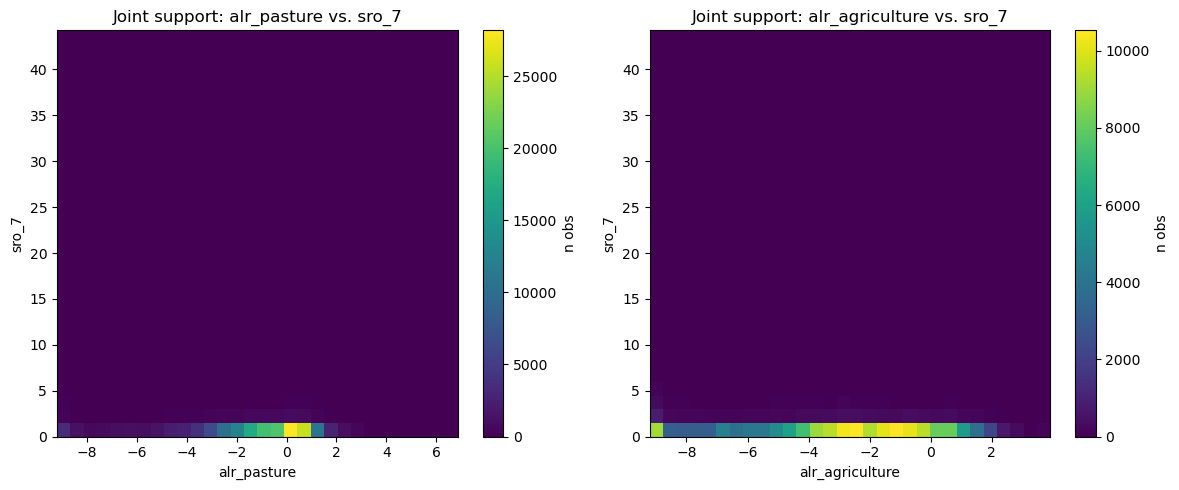

In [32]:
# Joint support of sro_7 and each interacted land-cover share: do high-share
# stations span the same runoff range as low-share ones, or only a sliver of
# it?
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, alr_col in zip(axes, ["alr_pasture", "alr_agriculture"]):
    sub = df[[alr_col, "sro_7"]].dropna()
    h = ax.hist2d(sub[alr_col], sub["sro_7"], bins=30, cmap="viridis")
    fig.colorbar(h[3], ax=ax, label="n obs")
    ax.set_xlabel(alr_col)
    ax.set_ylabel("sro_7")
    ax.set_title(f"Joint support: {alr_col} vs. sro_7")
plt.tight_layout()
plt.show()

### 2.8 Fixed-effect cell sizes for `station_code + biome^year`

`fixest::feols` silently drops any observation that is the sole member of
one of its fixed-effect groups (a "singleton"), since such an observation
would otherwise be fit exactly by its own dummy. `station_code` (additive)
and `biome^year` (a full biome-by-year dummy set) are two separate
structures a reading can be singleton in; the counts below are a lower
bound on what would be dropped -- fixest's singleton removal is iterative,
so dropping one observation can turn a previously-fine group into a new
singleton, and this doesn't chase that cascade.

In [33]:
station_n = df.groupby("station_code")["station_code"].transform("size")
biome_year_n = df.groupby(["biome", "year"])["biome"].transform("size")

n_singleton_station_obs = int((station_n == 1).sum())
n_singleton_biome_year_obs = int((biome_year_n == 1).sum())
n_either_singleton = int(((station_n == 1) | (biome_year_n == 1)).sum())

print(f"Observations that are their station's only reading: {n_singleton_station_obs:,} of {len(df):,}")
print(f"Observations in a biome-year cell with only 1 reading: {n_singleton_biome_year_obs:,} of {len(df):,}")
print(
    "Observations affected by either (lower bound before iterative cascade): "
    f"{n_either_singleton:,} of {len(df):,} ({n_either_singleton / len(df):.2%})"
)

Observations that are their station's only reading: 126 of 209,157
Observations in a biome-year cell with only 1 reading: 4 of 209,157
Observations affected by either (lower bound before iterative cascade): 130 of 209,157 (0.06%)


### 2.9 Land-cover change magnitude and panel continuity (for a distributed-lag design)

Spec 2's distributed lag needs land cover to actually change from one year
to the next, and needs those year-to-year observations to be roughly
annual so a lag index `k` means the same thing everywhere. Section 2.5
already found only 0.9-4.5% of each `alr_*` regressor's variance survives
station-demeaning; this quantifies that finding directly in the units the
lag design cares about -- the size of a typical one-observation-to-the-next
change, and how many calendar years that step actually spans.

In [34]:
ALR_ANNUAL = (
    df.groupby(["station_code", "year"])[ALR_COLS]
    .mean()
    .reset_index()
    .sort_values(["station_code", "year"])
)
ALR_ANNUAL["year_gap"] = ALR_ANNUAL.groupby("station_code")["year"].diff()

delta = ALR_ANNUAL.groupby("station_code")[ALR_COLS].diff()
delta.columns = [f"delta_{c}" for c in ALR_COLS]
ALR_ANNUAL = pd.concat([ALR_ANNUAL, delta], axis=1)

transitions = ALR_ANNUAL.dropna(subset=["year_gap"])
print(f"{len(transitions):,} station-to-next-observed-year transitions.")
print(
    f"{(transitions['year_gap'] == 1).mean():.1%} are exactly 1 calendar year apart "
    "(the resolution a 5-lag annual distributed-lag design assumes)."
)
print("\nDistribution of the gap itself (years):")
transitions["year_gap"].describe()

58,938 station-to-next-observed-year transitions.
87.7% are exactly 1 calendar year apart (the resolution a 5-lag annual distributed-lag design assumes).

Distribution of the gap itself (years):


count    58938.000000
mean         1.444348
std          2.139532
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         38.000000
Name: year_gap, dtype: float64

In [35]:
# Typical size of a one-step land-cover change, vs. how much the level
# varies across the whole panel -- a small ratio means individual annual
# lag coefficients are being asked to identify a small wobble on top of an
# almost-fixed baseline.
delta_cols = [f"delta_{c}" for c in ALR_COLS]
level_std = df[ALR_COLS].std()
change_std = transitions[delta_cols].std()
change_std.index = ALR_COLS

comparison = pd.DataFrame({
    "level_std": level_std,
    "typical_1step_change_std": change_std,
    "ratio": change_std / level_std,
}).sort_values("ratio")
comparison

,level_std,typical_1step_change_std,ratio
alr_urban,2.397335,0.083435,0.034803
alr_pasture,2.188926,0.120875,0.055221
alr_mining,1.459964,0.095061,0.065112
alr_agriculture,2.972647,0.216506,0.072833
alr_other,1.333183,0.171685,0.128778
